# **BÁO CÁO ĐỒ ÁN MÔN HỌC: LẬP TRÌNH SONG SONG**

## **FINAL PROJECT_MIDTERM**


## **1. Thông Tin Nhóm & Kế Hoạch Triển Khai**

### **1.1. Thông tin thành viên nhóm**



| STT | Họ và Tên | MSSV | Vai trò |
| :--- | :--- | :--- | :--- |
| 1 | Trần Chấn Hiệp | 23122026 | Thành viên |
| 2 | Võ Ngọc Hiếu | 23122027 | Trưởng nhóm |
| 3 | Lý Nguyên Thương | 23122055 | Thành viên |

### **1.2. Bảng phân công công việc chi tiết**

| Phiên bản & Giai đoạn | Lý Nguyên Thương | Võ Ngọc Hiếu | Trần Chấn Hiệp |
| :--- | :--- | :--- | :--- |
| Thu thập & Chuẩn bị Dataset | Chụp và tiền xử lý Site 1 (Indoor) theo 3 độ phân giải | Chụp và tiền xử lý Site 2 (Outdoor) theo 3 độ phân giải | Chụp và tiền xử lý Site 3 (Tự chọn) & Cặp Challenging <br>theo 3 độ phân giải |
| V0: Baseline Tuần tự (C++) | Cài đặt và kiểm thử Stages 1-2<br>(Grayscale, Gaussian Blur 2D, Harris Detector) | Cài đặt và kiểm thử Stages 3-4<br>(Rotated BRIEF 256-bit, Brute-force Matching) | Cài đặt và kiểm thử Stages 5-6<br>(RANSAC Normalized DLT, Warping/Feathering) |
| V1: CUDA Cơ bản (Naive Kernels) | Cài đặt kernel CUDA cho Stages 1-2<br>(1 thread/pixel, gom điểm bằng atomic) | Cài đặt kernel CUDA cho Stages 3-4<br>(1 thread/keypoint, so khớp toàn cục $N_A \times N_B$) | Cài đặt kernel CUDA cho Stage 6 (Inverse Warping/Bilinear),<br>điều phối Stage 5 & tích hợp main |
| V2: Tối ưu hóa Bộ nhớ (Memory Hierarchy) | Tách bộ lọc Gaussian Separable 1D, nạp Shared Memory<br>kèm Halo cho Stages 1-2 | Chuyển 256 cặp BRIEF vào `__constant__` memory<br>& nạp patch vào Shared Memory (Stage 3) | Tối ưu hóa truy cập bộ nhớ coalesced và nạp dữ liệu ảnh<br>song song cho Warping Stage 6 |
| V3: Tối ưu Tính toán & Warp Level | Hiện thực Stream Compaction / Parallel Reduction để<br>gom Top-K keypoint Stage 2 | Tối ưu Tiled Matching với `__popc` trên Shared<br>Memory (Stage 4) | Song song hóa RANSAC dùng `__shfl_down_sync` trên<br>GPU (Stage 5) |
| V4: Tối ưu Pipeline & Streams | Cấu hình stream độc lập xử lý Stages 1-3 cho Ảnh A | Cấu hình stream độc lập xử lý Stages 1-3 cho Ảnh B<br>chạy song song với Ảnh A | Áp dụng Pinned Memory (`cudaMallocHost`), gộp kernel<br>và loại bỏ truyền nhận trung gian PCIe |
| Báo cáo, Video Demo & Vấn đáp | Viết nội dung báo cáo phân tích Stages 1-2, chuẩn bị<br>slide trình chiếu | Soạn thảo kịch bản, quay dựng video demo chạy code<br>và phân tích speedup | Tổng hợp bảng số liệu benchmark 3 độ phân giải, hoàn thiện<br>báo cáo và chuẩn bị vấn đáp |

### **1.3. Lộ trình thực hiện dự kiến**


* **Tuần 7 (Midterm):** Hoàn thành *baseline tuần tự V0*, đo đạc thời gian, phân tích Amdahl, chuẩn bị bộ Dataset chuẩn.
* **Tuần 9 - 10:** Triển khai *V1* - Chuyển toàn bộ 6 stages lên GPU với kernel đơn giản, đảm bảo kết quả đồng nhất với V0.
* **Tuần 11 - 12:** Triển khai *V2* & *V3* - Tách bộ lọc 1D, tận dụng Shared Memory, Constant Memory, `__popc`, và tối ưu RANSAC.
* **Tuần 13 - 14:** Triển khai *V4* - Sử dụng CUDA Streams chạy song song Ảnh A và Ảnh B, Pinned Memory.
* **Tuần 15:** Hoàn thiện báo cáo, quay video demo, benchmark toàn diện và chuẩn bị vấn đáp.

## **2. Tổng Quan Bài Toán & Mô Tả Pipeline**

### **2.1. Đặt vấn đề và cơ sở lý thuyết**

Ghép ảnh toàn cảnh (Panorama Image Stitching) là bài toán kết hợp hai hoặc nhiều bức ảnh chụp cùng một khung cảnh từ các góc nhìn khác nhau thành một bức ảnh góc rộng duy nhất, liền mạch mà vẫn giữ được tính chân thực của cảnh vật.

Theo yêu cầu đồ án, nhóm em cần thu thập hai ảnh chụp cùng một khung cảnh với độ chồng lấp từ 30% đến 50%. Quá trình chụp có một nguyên tắc bắt buộc phải tuân theo: Người chụp phải đứng yên tại một chỗ và chỉ xoay máy ảnh quanh trục, không được vừa đi vừa chụp.

Lý do cần tuân thủ nghiêm ngặt điều này là vì nếu di chuyển vị trí đứng, ảnh chụp sẽ bị dính hiện tượng parallax (hiện tượng thị sai). Các vật ở gần và vật ở xa sẽ bị lệch góc nhìn khác nhau, lúc này không có một phép biến đổi 2D nào có thể ghép khớp được toàn bộ khung cảnh và ảnh ghép chắc chắn sẽ bị bóng mờ. Ngược lại, khi máy ảnh chỉ xoay quanh tâm quang học, vị trí giữa hai bức ảnh sẽ tuân theo một phép biến đổi phẳng 2D, biểu diễn bằng ma trận Homography $H$ kích thước $3 \times 3$ với 8 ẩn số:
$$\begin{bmatrix} x_A \\ y_A \\ 1 \end{bmatrix} \sim H \begin{bmatrix} x_B \\ y_B \\ 1 \end{bmatrix}$$

Mục tiêu chính của cả chương trình là từ hai ảnh ban đầu, thuật toán phải tự tìm ra được ma trận $H$ này để nắn và chiếu ảnh *Image B* về cùng hệ tọa độ với ảnh *Image A*. Sau khi hai ảnh đã khớp hình học với nhau, bước cuối cùng là hòa trộn vùng đè lên nhau sao cho ảnh panorama xuất ra nhìn tự nhiên, không bị lộ vệt cắt nối hay bị lệch màu giữa hai ảnh.


### **2.2. Sơ đồ tổng quan luồng xử lý 6 giai đoạn**

Để giải quyết bài toán một cách tự động và ổn định, quy trình xử lý của nhóm được chia làm hai khối lớn với tổng cộng sáu giai đoạn tuần tự (Sơ đồ Mermaid bên dưới). Các bước **Stage 1 → Stage 3** chạy hoàn toàn độc lập trên từng ảnh (rất thuận lợi để phân bổ vào 2 stream song song trên GPU). Từ **Stage 4 → Stage 6**, dữ liệu của cả hai ảnh được kết hợp lại.





In [1]:
# @title
from IPython.display import HTML, display

mermaid_code = """
%%{init: {
  'theme': 'base',
  'flowchart': {
    'curve': 'linear',
    'htmlLabels': true,
    'nodeSpacing': 50,
    'rankSpacing': 45,
    'padding': 20
  },
  'themeVariables': {
    'fontFamily': 'Segoe UI, Arial, sans-serif',
    'fontSize': '13px',
    'primaryBorderColor': '#555'
  }
}}%%
flowchart TD
    classDef io fill:#2b579a,stroke:#1e3f70,stroke-width:2px,color:#fff,font-weight:bold;
    classDef branchA fill:#e3f2fd,stroke:#1e88e5,stroke-width:1.5px,color:#0d47a1;
    classDef branchB fill:#fff3e0,stroke:#fb8c00,stroke-width:1.5px,color:#e65100;
    classDef merge fill:#f3e5f5,stroke:#8e24aa,stroke-width:1.5px,color:#4a148c;
    classDef finalStage fill:#e8f5e9,stroke:#43a047,stroke-width:1.5px,color:#1b5e20;

    subgraph Input["Đầu vào (RGB Images)"]
        ImgA(["Ảnh Trái (Image A - RGB)"]):::io
        ImgB(["Ảnh Phải (Image B - RGB)"]):::io
    end

    subgraph Block1["Khối 1: Trích xuất đặc trưng độc lập"]
        subgraph Stage1["Stage 1: Tiền xử lý"]
            GrayA("Grayscale (float)"):::branchA --> BlurA("Gaussian Blur 2D<br/>(5x5, σ = 1.4)"):::branchA
            GrayB("Grayscale (float)"):::branchB --> BlurB("Gaussian Blur 2D<br/>(5x5, σ = 1.4)"):::branchB
        end

        subgraph Stage2["Stage 2: Phát hiện điểm góc"]
            SobelA("Sobel 3x3 (Ix, Iy)"):::branchA --> HarrisA("Ma trận cấu trúc M<br/>& Harris R"):::branchA --> NMSA("NMS 5x5 + Top-K<br/>(3000 keypoints)"):::branchA
            SobelB("Sobel 3x3 (Ix, Iy)"):::branchB --> HarrisB("Ma trận cấu trúc M<br/>& Harris R"):::branchB --> NMSB("NMS 5x5 + Top-K<br/>(3000 keypoints)"):::branchB
        end

        subgraph Stage3["Stage 3: Mô tả đặc trưng"]
            AngleA("Góc hướng θ<br/>(Intensity Centroid)"):::branchA --> DescA("Rotated BRIEF 256-bit<br/>(8 x uint32)"):::branchA
            AngleB("Góc hướng θ<br/>(Intensity Centroid)"):::branchB --> DescB("Rotated BRIEF 256-bit<br/>(8 x uint32)"):::branchB
        end
    end

    subgraph Block2["Khối 2: Kết hợp thông tin và tạo ảnh toàn cảnh"]
        subgraph Stage4["Stage 4: So khớp đặc trưng"]
            Hamming("Khoảng cách Hamming<br/>(XOR + popcount)"):::merge --> Filter("Lowe's Ratio Test (0.75)<br/>+ Mutual Cross-Check"):::merge
        end

        subgraph Stage5["Stage 5: Ước lượng Homography"]
            RANSAC("<b>RANSAC 2000 vòng (4-point DLT + Hartley Norm)</b><br/><span style='font-size:11px; color:#555;'><i>Sử dụng tọa độ Keypoints A & B từ Stage 2</i></span>"):::merge --> Refine("Least-Squares Refinement<br/>trên toàn bộ Inliers"):::merge
        end

        subgraph Stage6["Stage 6: Biến đổi hình học & Hòa trộn"]
            BBox("Tính Bounding Box khung hình"):::finalStage --> Warp("<b>Inverse Warping (H⁻¹) + Nội suy Bilinear</b><br/><span style='font-size:11px; color:#2e7d32;'><i>Biến đổi trên Ảnh Phải Gốc RGB</i></span>"):::finalStage --> Blend("<b>Linear Feathering theo khoảng cách biên</b><br/><span style='font-size:11px; color:#2e7d32;'><i>Hòa trộn với Ảnh Trái Gốc RGB</i></span>"):::finalStage
        end
    end

    Output(["Ảnh Panorama Hoàn Chỉnh (RGB)"]):::io

    %% Luồng xử lý chính thẳng trục đối xứng hoàn toàn
    ImgA --> GrayA
    ImgB --> GrayB

    BlurA --> SobelA
    BlurB --> SobelB

    NMSA --> AngleA
    NMSB --> AngleB

    DescA --> Hamming
    DescB --> Hamming

    Filter --> RANSAC
    Refine --> BBox
    Blend --> Output

    style Input fill:#f8f9fa,stroke:#adb5bd,stroke-width:1.5px,stroke-dasharray: 5 5
    style Block1 fill:#ffffff,stroke:#90caf9,stroke-width:2px
    style Block2 fill:#ffffff,stroke:#ce93d8,stroke-width:2px
    style Stage1 fill:#fafafa,stroke:#dcdcdc
    style Stage2 fill:#fafafa,stroke:#dcdcdc
    style Stage3 fill:#fafafa,stroke:#dcdcdc
    style Stage4 fill:#fafafa,stroke:#dcdcdc
    style Stage5 fill:#fafafa,stroke:#dcdcdc
    style Stage6 fill:#fafafa,stroke:#dcdcdc
"""

display(HTML(f'''
<style>
    /* Đảm bảo chữ trong hộp không bị cắt */
    .mermaid .nodeLabel {{
        padding: 4px 14px !important;
        display: inline-block !important;
        line-height: 1.4 !important;
    }}
    /* Đẩy tiêu đề Subgraph sang góc trái và tạo nền che mũi tên cắt qua chữ */
    .mermaid .cluster-label {{
        background-color: #ffffff !important;
        padding: 2px 8px !important;
        border-radius: 4px !important;
    }}
    .mermaid .cluster-label .nodeLabel {{
        background-color: #ffffff !important;
        padding: 2px 10px !important;
        font-weight: bold !important;
        color: #222 !important;
        border-radius: 4px !important;
        box-shadow: 0 0 0 3px #ffffff !important;
    }}
</style>
<div style="display: flex; justify-content: center; background: #ffffff; padding: 30px; border-radius: 12px; box-shadow: 0 4px 12px rgba(0,0,0,0.08);">
    <div class="mermaid" style="width: 100%; display: flex; justify-content: center;">
{mermaid_code}
    </div>
</div>
<script src="https://cdn.jsdelivr.net/npm/mermaid@10/dist/mermaid.min.js"></script>
<script>
    mermaid.initialize({{ startOnLoad: false, securityLevel: 'loose' }});
    setTimeout(() => {{
        mermaid.run({{ querySelector: '.mermaid' }});
    }}, 200);
</script>
'''))

#### **Bảng tóm tắt luồng dữ liệu trung gian giữa các Stage**

Bảng dưới đây mô tả chi tiết định dạng, kích thước và cấu trúc dữ liệu được luân chuyển xuyên suốt toàn bộ pipeline:

| Stage | Input | Output | Kiểu dữ liệu & Kích thước | Ý nghĩa |
| :--- | :--- | :--- | :--- | :--- |
| **Input** | Hai file ảnh chụp (`.jpg` / `.png`) | `Image imgA, imgB` | `uint8_t*` ($W \times H \times 3$) | Đọc 2 bức ảnh gốc vào bộ nhớ dưới dạng các điểm ảnh màu RGB. |
| **1. Preprocessing** | `Image imgA, imgB` | `blurA, blurB` | `std::vector<float>` ($W \times H$) | Đổi sang ảnh đen trắng và làm mờ nhẹ để xóa hạt nhiễu, giúp tìm góc chính xác hơn. |
| **2. Keypoint Detection** | `blurA, blurB` | `kpA, kpB` | `std::vector<Keypoint>` ($\le 3000$ phần tử) | Quét ảnh tìm các góc nhọn nổi bật nhất (như góc bàn, mép tường, ngọn cây). |
| **3. Description** | `blurA, blurB` + `kpA, kpB` | `descA, descB` | `std::vector<Descriptor>` ($\le 3000 \times 32\text{ bytes}$) | Tạo "dấu vân tay" nhị phân cho từng góc để máy nhận diện được điểm đó dù ảnh bị xoay. |
| **4. Feature Matching** | `descA, descB` | `matches` | `std::vector<Match>` ($M$ cặp tương ứng) | So khớp "dấu vân tay" giữa 2 ảnh, chọn ra các cặp điểm thực sự thuộc cùng 1 vị trí ngoài đời. |
| **5. Homography** | `kpA, kpB` + `matches` | Ma trận `H` | Struct `Homography` (`double h[9]`, $3\times 3$) | Tìm công thức toán học (ma trận xoay/nghiêng) để bẻ cong ảnh B sao cho khớp khít vào ảnh A. |
| **6. Warping & Blending**| `imgA, imgB` + `H` | `Image pano` | `uint8_t*` ($W_{\text{out}} \times H_{\text{out}} \times 3$) | Uốn nắn ảnh B theo công thức, đặt cạnh ảnh A và xóa mờ vết nối để ra ảnh toàn cảnh mượt mà. |

## **3. Lựa Chọn Thuật Toán & Cơ Sở Thiết Kế**

### **3.1. Khối 1: Trích xuất đặc trưng độc lập (Stages 1 - 3)**

Ở ba giai đoạn đầu, ảnh A và ảnh B được xử lý hoàn toàn độc lập với nhau vì chúng hoàn toàn không phụ thuộc dữ liệu lẫn nhau. Việc tách riêng này rất có lợi khi áp dụng lập trình song song: Xử lý đồng thời cả hai ảnh trên hai luồng CPU riêng, hoặc đẩy vào hai CUDA stream độc lập để tận dụng tối đa năng lực tính toán của GPU.
- **Giai đoạn 1 - Tiền xử lý (Preprocessing):** Ảnh màu RGB gốc chứa ba kênh màu với khối lượng dữ liệu lớn và chứa nhiều thông tin màu không cần thiết cho việc tìm kiếm đặc trưng hình học. Do đó, nhóm xử lý qua 2 bước:
  - **Chuyển sang ảnh xám (Grayscale):** Sử dụng công thức chuẩn quang học theo độ nhạy của mắt người: $Y = 0.299R + 0.587G + 0.114B$. Giá trị điểm ảnh sau khi chuyển được lưu dưới dạng số thực `float` thuộc $[0.0; 255.0]$ thay vì số nguyên `uint8_t` để giữ độ chính xác cho các phép tính vi phân ở bước sau mà không bị tràn số hay mất mát do làm tròn.
  - **Làm mịn bằng Gaussian Blur 2D:** Sử dụng cửa sổ lọc kích thước $5 \times 5$ (với bán kính `radius = 2`) với độ lệch chuẩn $\sigma = 1.4$. Đây là kích thước tiêu chuẩn trong xử lý ảnh, đủ rộng để khử triệt để các nhiễu hạt cảm biến ở tần số cao nhưng lại không làm nhòe quá mức các góc cạnh. Nếu bỏ qua bước này, các toán tử đạo hàm Sobel ở Stage 2 sẽ bắt nhầm các điểm nhiễu lấm tấm thành góc nhọn, dẫn đến việc tìm sai đặc trưng.
- **Giai đoạn 2 - Phát hiện điểm đặc trưng (Keypoint Detection):** Để ghép được hai bức ảnh, chương trình cần tìm ra những điểm góc (corners) nổi bật, có tính lặp lại cao dù góc chụp hoặc ánh sáng có thay đổi nhẹ. Nhóm sử dụng thuật toán *Harris Corner Detector* với các bước cụ thể như sau:
  - **Tính Gradient:** Dùng hai bộ lọc Sobel $3 \times 3$ để tính đạo hàm theo trục ngang ($I_x$) và trục dọc ($I_y$). Sau đó tính các thành phần tích: $I_x^2$, $I_y^2$ và $I_x I_y$.
  - **Xây dựng ma trận cấu trúc $M$:** Để xây dựng ma trận cấu trúc cục bộ $M$, ta tính tổng các tích trên trong một cửa sổ trượt $3 \times 3$ để tạo ma trận $M$. Một điểm được xem là điểm góc mạnh nếu cường độ sáng thay đổi rõ rệt theo mọi hướng (cả hai trị riêng của ma trận cấu trúc $M$ đều lớn).
  - **Điểm phản hồi Harris $R$:** Điểm phản hồi góc $R$ được tính theo công thức:
  $$R = \det(M) - k \cdot (\operatorname{trace}(M))^2 = (S_{xx} S_{yy} - S_{xy}^2) - 0.04 \cdot (S_{xx} + S_{yy})^2$$
  Trong đó hệ số nhạy cảm $k = 0.04$ là hằng số kinh điển do Harris và Stephens đề xuất, giúp cân bằng độ nhạy giữa góc và cạnh. Giá trị $R$ càng lớn thì điểm góc càng rõ rệt.
  - **Lọc biên và triệt tiêu cực đại cục bộ (Non-Maximum Suppression - NMS):** Áp dụng cửa sổ Non-Maximum Suppression kích thước $5 \times 5$ để triệt tiêu các cực đại cục bộ. Cụ thể, trong mỗi cửa sổ $5 \times 5$, ta sẽ chỉ giữ lại điểm có $R > 10^4$ và đồng thời phải là điểm lớn nhất trong toàn bộ 24 điểm lân cận. Ngoài ra, chương trình sẽ bỏ qua các điểm nằm quá sát mép ảnh (cách biên $< 16\text{ px}$) để chừa khoảng trống cho việc trích xuất vùng lân cận ở Stage 3.
  - **Top-$K$ Selection:** Do số lượng góc vượt ngưỡng rất nhiều (có thể lên tới hàng chục nghìn điểm), nhóm em dùng `std::partial_sort` để chỉ lấy đúng $K = 3000$ điểm mạnh nhất (có giá trị $R$ cao nhất). Việc cố định $K = 3000$ vừa giúp thuật toán không bị quá tải tính toán ở bước so khớp $O(K^2)$ phía sau, vừa đảm bảo phân bố đủ mật độ đặc trưng để tìm ra các cặp điểm khớp chất lượng.
- **Giai đoạn 3 - Mô tả đặc trưng (Feature Description):** Sau khi đã xác định được vị trí của $K$ điểm đặc trưng góc, để so sánh được các keypoint giữa hai ảnh, chương trình cần gắn cho mỗi điểm một "dấu vân tay" độc nhất dưới dạng một vector mô tả (chuỗi bit nhị phân gọn nhẹ). Nhóm sử dụng phương pháp *Rotated BRIEF (rBRIEF 256-bit)* chuẩn ORB vì sự gọn nhẹ và chạy rất nhanh với các bước cụ thể như sau:
  - **Tính góc hướng (Orientation) bằng Intensity Centroid:** Khi người dùng chụp panorama bằng tay, việc nghiêng hoặc xoay nhẹ máy ảnh giữa hai lần bấm là không thể tránh khỏi. Để giải quyết, với mỗi keypoint, thuật toán xét một vùng tròn bán kính $r = 15$ pixel xung quanh và tính trọng tâm cường độ sáng:
  $$m_{10} = \sum_{u, v} u \cdot I(x + u, y + v)$$
  $$m_{01} = \sum_{u, v} v \cdot I(x + u, y + v)$$
  Góc hướng của keypoint được xác định bởi:
  $$\theta = \operatorname{atan2}(m_{01}, m_{10})$$
  - **Tạo chuỗi nhị phân 256-bit:** Nhóm sử dụng một mẫu cố định gồm 256 cặp tọa độ điểm tương đối $(p_1, p_2)$ được sinh ngẫu nhiên từ trước (dùng cố định `seed 42`). Trước khi so sánh, 256 cặp điểm này được xoay theo góc $\theta$ vừa tính bằng ma trận xoay 2D. Sau đó, thuật toán so sánh cường độ sáng giữa hai điểm: nếu điểm thứ nhất tối hơn điểm thứ hai thì ghi nhận bit $1$, ngược lại ghi $0$. Kết quả thu được là một chuỗi nhị phân 256-bit, mang đầy đủ tính bất biến với góc xoay 2D và độ tương phản sáng tối cục bộ. Toàn bộ 256 bit này được đóng gói gọn gàng vào mảng gồm 8 số nguyên 32-bit (`uint32_t bits[8]`). <br>$⇒$ Mỗi descriptor như vậy chỉ tốn đúng *32 bytes* bộ nhớ (nhỏ hơn 16 lần so với SIFT dùng 128 số float tốn 512 bytes). Điều này cực kỳ có lợi khi chuyển sang GPU vì tiết kiệm băng thông bộ nhớ và tăng tốc độ đọc ghi đáng kể.


### **3.2. Khối 2: Kết hợp thông tin và tạo toàn cảnh (Stages 4 - 6)**

Bắt đầu từ giai đoạn 4, dữ liệu đặc trưng của cả hai bức ảnh được đưa vào đối chiếu và kết hợp lại để tìm ra mối quan hệ hình học và ghép nối:
- **Giai đoạn 4 - Khớp nối đặc trưng (Feature Matching):** Chương trình tiến hành so sánh toàn bộ các descriptor của ảnh A với ảnh B để tìm ra các cặp điểm tương ứng:
  - **Khoảng cách Hamming:** Do mô tả rBRIEF có dạng nhị phân 256-bit (`uint32_t bits[8]`), khoảng cách giữa hai descriptor được tính cực kỳ nhanh bằng phép toán XOR kết hợp với hàm đếm số bit $1$ trong phần cứng (`__builtin_popcount`). Tổng số bit khác nhau chính là khoảng cách Hamming (giá trị từ 0 đến 256).
  - **Bộ lọc kép loại bỏ điểm khớp sai:** Trong ảnh thực tế thường xuất hiện các vùng có cấu trúc lặp lại (như gạch lát nền, cửa sổ, hàng rào) dễ dẫn đến việc so khớp nhầm. Để khắc phục, nhóm áp dụng đồng thời hai tầng lọc:
    - **Lowe's Ratio Test:** Với mỗi điểm ở ảnh A, tìm điểm gần nhất ($d_1$) và gần nhì ($d_2$) ở ảnh B. Chỉ chấp nhận cặp khớp nếu khoảng cách vượt trội rõ rệt: $d_1 < 0.75 \times d_2$ (ngưỡng 0.75 là tiêu chuẩn kinh điển của Lowe giúp loại bỏ các điểm khớp mơ hồ) và khoảng cách tối đa không vượt quá 64.
    - **Mutual Cross-Check:** Ta thực hiện kiểm tra chéo: Điểm $i$ ở ảnh A khi tìm điểm gần nhất là $j$ ở ảnh B, thì ngược lại, khi lấy điểm $j$ tìm điểm gần nhất ở ảnh A cũng phải trả về đúng điểm $i$. Sự kết hợp này giúp lọc bỏ gần như toàn bộ các điểm khớp nhiễu (outliers) ngay từ đầu.
- **Giai đoạn 5 - Ước lượng Homography (Homography Estimation):** Mặc dù bước lọc và so khớp đã loại bỏ được nhiều sai lệch, tập dữ liệu ghép nối vẫn khó tránh khỏi một số cặp điểm bị lệch do vật thể chuyển động hoặc sai số cận biên. Do đó, thuật toán *RANSAC (Random Sample Consensus)* được sử dụng để tìm ma trận chiếu xạ 3x3 ($H$):
  - **Lặp RANSAC (2000 vòng):** Chương trình lặp lại 2000 lần việc chọn ngẫu nhiên 4 cặp điểm khớp phân biệt để thiết lập giả thuyết về ma trận $H$. Việc lặp lại đến 2000 lần đảm bảo xác suất tìm thấy tập inlier thuần khiết rất cao ngay cả khi tỷ lệ outlier lớn.
  - **Chuẩn hóa Hartley:** Ở các độ phân giải cao, tọa độ pixel rất lớn khiến các số hạng trong ma trận bị chênh lệch hàng triệu lần, gây mất ổn định số học. Vì vậy, trước khi giải, tọa độ các điểm sẽ cần được dịch tâm về $(0,0)$ và co giãn sao cho khoảng cách trung bình đến gốc tọa độ bằng $\sqrt{2}$.
  - **Giải hệ phương trình $8 \times 8$ & Đếm Inliers:** Với mỗi vòng lặp, lập hệ phương trình chuẩn $A^T A h = A^T b$ và giải trực tiếp bằng phương pháp Khử Gauss có chọn phần tử trụ mà không cần dùng thư viện ngoài để có được ma trận ứng viên. Sau đó, đem ma trận ứng viên chiếu thử toàn bộ các cặp điểm còn lại, đếm số lượng điểm đồng thuận Inliers (Inliers có sai số tái chiếu bình phương nhỏ hơn ngưỡng $3.0\text{ px}$).
  - **Tinh chỉnh:** Sau 2000 vòng lặp, hệ thống chọn ra mô hình ứng viên $H$ tốt nhất (có tập Inliers lớn nhất). Toàn bộ tập điểm đồng thuận này sẽ được đưa qua bước tối ưu hóa bằng phương pháp bình phương tối thiểu để tính lại ma trận $H$, giúp nâng cao độ chính xác đạt mức dưới pixel (sub-pixel accuracy, kiểm thử thực tế ghi nhận sai số $\approx 0.1\text{ px}$).
- **Giai đoạn 6 - Biến đổi hình học và Hòa trộn (Warping and Blending):** Có được ma trận Homography $H$, bước cuối cùng là dựng nên bức ảnh Panorama hoàn chỉnh:
  - **Xác định Bounding Box:** Chiếu 4 góc của ảnh B qua $H$ sang hệ tọa độ của ảnh A để xác định kích thước khung ảnh đích chứa trọn vẹn cả hai bức ảnh.
  - **Chiếu ngược (Inverse Warping) & Nội suy Bilinear:** Thay vì chiếu thuận từ ảnh B sang ảnh A (dễ gây ra các lỗ hổng pixel trống do làm tròn tọa độ), chương trình dùng ma trận nghịch đảo $H^{-1}$ để chiếu ngược từng pixel trên khung ảnh đích về lại tọa độ thực trên ảnh B. Giá trị màu của pixel được lấy thông qua *nội suy song tuyến tính (Bilinear Interpolation)* từ 4 điểm nguyên lân cận để ảnh không bị vỡ hạt hay răng cưa.
  - **Hòa trộn theo khoảng cách biên:** Tại vùng giao thoa nơi cả ảnh A và ảnh B cùng phủ lên, chương trình tính khoảng cách từ điểm đó tới mép biên gần nhất của từng ảnh để làm trọng số hòa trộn ($\alpha = \frac{d_A}{d_A + d_B}$). Điểm càng gần biên ảnh nào thì ảnh đó càng chiếm tỷ trọng lớn. Nhờ cách tính này, vết cắt giữa hai bức ảnh được xóa mờ hoàn toàn, tạo ra bức ảnh panorama liền mạch, tự nhiên và không bị lệch màu.

### **3.3. Bảng tổng hợp phương pháp, tham số và lập luận kỹ thuật**

Để hoàn thành đồ án, nhóm đã nghiên cứu, lựa chọn và hiện thực hóa các phương pháp cho từng giai đoạn trong pipeline. Bảng tổng hợp dưới đây trình bày chi tiết các phương pháp, tham số cốt lõi và lập luận kỹ thuật (vừa đảm bảo chất lượng đầu ra, vừa phù hợp để hiện thực hóa trên GPU):

| Giai đoạn | Phương pháp đã chọn | Tham số chính | Chất lượng và tính phù hợp khi đưa lên GPU |
| :--- | :--- | :--- | :--- |
| **1. Tiền xử lý** | Grayscale + Làm mờ Gaussian 2D | Kernel $5 \times 5$ ($r=2$),<br>$\sigma = 1.4$ | Giúp khử sạch nhiễu hạt cảm biến trước khi tính đạo hàm. Cấu trúc lọc lân cận<br>2D rất đồng nhất, hoàn toàn phù hợp để phân phối cho các thread block trên<br>GPU và dễ dàng tách thành 1D ở các phiên bản tối ưu bộ nhớ tiếp theo. |
| **2. Phát hiện điểm đặc trưng** | Harris Corner Detector + NMS +<br>Top-$K$ | $k = 0.04$,<br>ngưỡng $= 10^4$,<br>cửa sổ NMS $5 \times 5$ ($r=2$),<br>$K = 3000$,<br>viền $= 16\text{ px}$ | Cho ra các điểm góc rất ổn định, không bị lệch khi ánh sáng thay đổi nhẹ.<br>Tránh được hiện tượng rẽ nhánh phức tạp như FAST (vốn gây hiện tượng nghẽn<br>phân kỳ luồng - warp divergence trên GPU). |
| **3. Mô tả đặc trưng** | Rotated BRIEF (rBRIEF 256-bit)<br>kèm Intensity Centroid | Vùng vá $31 \times 31$ ($r=15$),<br>256 cặp điểm (`8 x uint32_t`),<br>seed 42 | Đảm bảo tính bất biến với góc quay nhờ định hướng tâm sáng. Mỗi descriptor<br>chỉ tốn vỏn vẹn 32 bytes (nhỏ hơn 16 lần so với SIFT), giúp tiết kiệm đáng kể<br>băng thông bộ nhớ toàn cục khi tính toán trên GPU. |
| **4. Khớp nối đặc trưng** | Brute-Force Hamming + Lowe's<br>Ratio Test + Mutual Cross-Check | Ngưỡng tỷ lệ $= 0.75$,<br>khoảng cách tối đa $= 64$ | Lọc bỏ triệt để các điểm khớp sai lệch. Bài toán so khớp toàn cục $N_A \times N_B$<br>chính là nút thắt đặc biệt để tận dụng shared memory và tập lệnh phần cứng<br>đếm bit`__popc` trên GPU, mang lại tốc độ vượt trội. |
| **5. Ước lượng Homography** | RANSAC + Hartley-Normalized DLT<br>+ Inlier Refinement | $2000$ vòng lặp,<br>ngưỡng sai số $= 3.0\text{ px}$,<br>seed 42 | Việc chuẩn hóa Hartley giúp giải quyết triệt để vấn đề mất ổn định số học khi<br>tọa độ ảnh lên tới hàng nghìn pixel ở độ phân giải cao. Tự viết hàm giải hệ $8 \times 8$<br>bằng khử Gauss giúp mã nguồn độc lập, không phụ thuộc thư viện ngoài. |
| **6. Biến đổi hình học & Hòa trộn** | Inverse Warping + Bilinear<br>Interpolation + Distance Feathering | Khung ảnh tự động co giãn,<br>nội suy bilinear,<br>trọng số $\alpha = \frac{d_A}{d_A + d_B}$ | Phép chiếu ngược (inverse mapping) đảm bảo ảnh không bị lọt các pixel trống,<br>kết hợp với feathering theo khoảng cách giúp che giấu hoàn toàn đường ranh<br>giới giao nhau giữa hai bức ảnh một cách mượt mà. |

## **4. Phiên Bản Tuần Tự Baseline - V0**

### **4.1. Mô tả kiến trúc mã nguồn C++**



Phiên bản $V_0$ là nền tảng tuần tự hoàn chỉnh được viết bằng C++ thuần, đóng vai trò là phiên bản chuẩn để đối chiếu độ chính xác và tốc độ cho các phiên bản CUDA sau này.

Đúng theo yêu cầu của đồ án, $V_0$ chạy hoàn toàn đơn luồng (single-threaded), không sử dụng bất kỳ kỹ thuật đa luồng nào như `OpenMP`, `std::thread` hay các tập lệnh SIMD thủ công. Toàn bộ pipeline gồm 6 giai đoạn được gói gọn trong hàm `stitch_v0` (tại `src/v0_sequential.cpp`) với các thành phần chính:
- **Giao tiếp dữ liệu:** Nhận đầu vào là hai cấu trúc `Image` (chứa con trỏ dữ liệu ảnh RGB dạng `uint8_t`, chiều rộng `width`, chiều cao `height`) và các tham số cấu hình `StitchParams`.
- **Cấu trúc dữ liệu trung gian:**
  - `std::vector<float>` lưu ảnh xám và ảnh sau khi làm mờ Gaussian.
  - `std::vector<Keypoint>` lưu tọa độ thực `(x, y)`, giá trị phản hồi góc `response`, và góc hướng `angle`.
  - `std::vector<Descriptor>` lưu chuỗi nhị phân 256-bit được đóng gói vào mảng `uint32_t bits[8]`.
  - `std::vector<Match>` lưu các cặp điểm khớp `idxA`, `idxB` kèm theo khoảng cách Hamming.
- **Tách biệt logic mã nguồn:** Toàn bộ thuật toán được viết độc lập, rõ ràng theo từng hàm tương ứng với các giai đoạn (từ `rgb_to_grayscale`, `detect_harris_keypoints`, `compute_rotated_brief_descriptors`, `match_descriptors`, `estimate_homography_ransac`, cho đến `warp_and_blend`). Mã nguồn tuân thủ nghiêm ngặt việc không sao chép code thừa trong notebook mà build trực tiếp từ thư mục `src/`.

### **4.2. Hướng dẫn biên dịch và kiểm thử trên Google Colab**



Khi chạy notebook trên Google Colab, quá trình thiết lập môi trường, biên dịch và kiểm thử phiên bản $V_0$ diễn ra qua các bước sau:

1. **Chuẩn bị và đồng bộ thư mục mã nguồn (`src/`):**
   Đảm bảo thư mục `src/` (chứa các file `.cpp`, `.cu`, `.h`, `.cuh`, `Makefile`) đã được tải lên môi trường Colab (hoặc mount từ Google Drive của nhóm):
   ```python
   !ls -la src/
   ```

2. **Biên dịch chương trình bằng lệnh `make`:**
   ```python
   !make clean
   !make
   ```
   *Lệnh này sẽ kích hoạt `nvcc` để biên dịch toàn bộ mã nguồn C++/CUDA trong thư mục `src/`, liên kết với thư viện `stb_image` và sinh ra tệp thực thi chính (ví dụ: `stitch`).*

3. **Chạy kiểm thử phiên bản V0:**
   Thực thi chương trình với cặp ảnh mẫu thuộc Dataset của nhóm (ví dụ: Site 1 ở độ phân giải Medium):
   ```python
   !./stitch dataset/site1/medium/img1.jpg dataset/site1/medium/img2.jpg output_pano.jpg --version 0 --runs 5
   ```
   *Trong đó:*
   - `--version 0`: Chỉ định chạy phiên bản tuần tự $V_0$.
   - `--runs 5`: Lặp lại 5 lần để tính thời gian trung bình khách quan cho từng stage.
   - Có thể đính kèm cờ `--gt dataset/site1/gt_homography.txt` nếu có ma trận ground-truth để kiểm tra sai số.

## **5. V0 results and profiling**

In [3]:
import os
!git clone https://github.com/iAmHieu2012/image-stitching.git
%cd image-stitching
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1I9BgEL_8Cngj2Z8MjeMReCGUq0ppzxUS?usp=drive_link"
if not os.path.exists("Dataset_ltss"):
    print("\n--- Đang tải bộ dữ liệu Dataset_ltss ---")
    !gdown --folder "{DRIVE_FOLDER_URL}" -O Dataset_ltss
else:
    print("\n--- Bộ dữ liệu Dataset_ltss đã tồn tại ---")

# 3. Tiến hành biên dịch bằng lệnh make

!make clean
!make

Cloning into 'image-stitching'...
remote: Enumerating objects: 69, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 69 (delta 3), reused 12 (delta 1), pack-reused 48 (from 2)
Receiving objects: 100% (69/69), 48.77 MiB | 50.44 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/image-stitching

--- Đang tải bộ dữ liệu Dataset_ltss ---
Retrieving folder contents
Retrieving folder 1MNU60ybou8fxauX20Xmrx2xetkh0xLFp challenge
Retrieving folder 1EEAmFJFvlGigzutWDcJXxJp1oH4SV-T9 1280x720
Processing file 1n_au2i6EXx_xsghj0sN0qgtARsoGnnRI img1.jpg
Processing file 14m2cdjPE9laNG7VdtpYHDjAWVO2-M2T0 img2.jpg
Retrieving folder 1q0P_IVFSY3Bd9O6u0vOKN1EWL7tnJMeB 1920x1080
Processing file 1jmlpXVP47UTaTzeha01cXTR2wNfWtWGA img1.jpg
Processing file 144SrQUTfbxrxejEIYzLWxWuA3D4K9c95 img2.jpg
Retrieving folder 1eh9JUM0V6wKqTqmyBaoyNwEU8VvL2fnP 3840x2160
Processing file 1N9XIz1tFG0DWi2QCfzbRhlgDVWyMOoyN img1.jpg
Processing file 1KfX5Zj

In [4]:
import os
import matplotlib.pyplot as plt
from PIL import Image
# 1. Thay đường link thư mục Dataset_ltss trên Google Drive của bạn vào đây:
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1I9BgEL_8Cngj2Z8MjeMReCGUq0ppzxUS?usp=drive_link"
# Tải nguyên thư mục Dataset_ltss về Colab (chỉ tải nếu chưa có)
if not os.path.exists("Dataset_ltss"):
    !gdown --folder "{DRIVE_FOLDER_URL}" -O Dataset_ltss
# 2. Tạo thư mục chứa ảnh đầu ra và chạy phiên bản V0
!mkdir -p output


### **5.1. Panorama đầu ra trên dataset của nhóm**

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/indoor/3840x2160/img1.jpg (3840 x 2160)
Input B    : Dataset_ltss/indoor/3840x2160/img2.jpg (3840 x 2160)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 109
RANSAC Inliers                : 8
Output Panorama Size          : 7156 x 3961
Estimated Homography H (B -> A):
  [     0.513898      0.062803   1247.313247 ]
  [    -0.167063      0.855467    109.896273 ]
  [    -0.000143      0.000011      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      576.705 |      497.356 |    29.88%
2. Keypoint Detection          |      177.798 |      168.115 |     9.21%
3. Description (rBRIEF)        |       79.745 |       74.556 |     4.13%
4. Featur

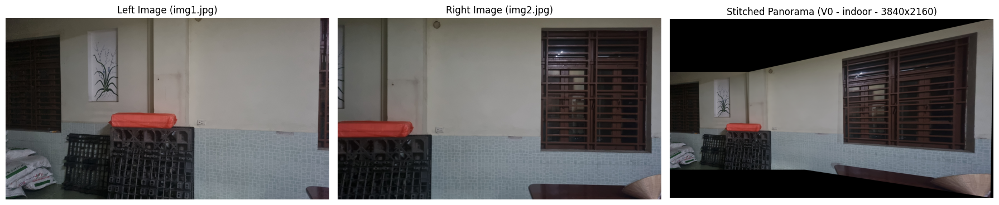

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/indoor/1920x1080/img1.jpg (1920 x 1080)
Input B    : Dataset_ltss/indoor/1920x1080/img2.jpg (1920 x 1080)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 192
RANSAC Inliers                : 48
Output Panorama Size          : 3041 x 1540
Estimated Homography H (B -> A):
  [     0.619275      0.029409    630.537038 ]
  [    -0.107441      0.866512     34.302934 ]
  [    -0.000207      0.000005      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      124.688 |      122.106 |    15.38%
2. Keypoint Detection          |       42.236 |       40.450 |     5.21%
3. Description (rBRIEF)        |       77.562 |       69.780 |     9.56%
4. Featu

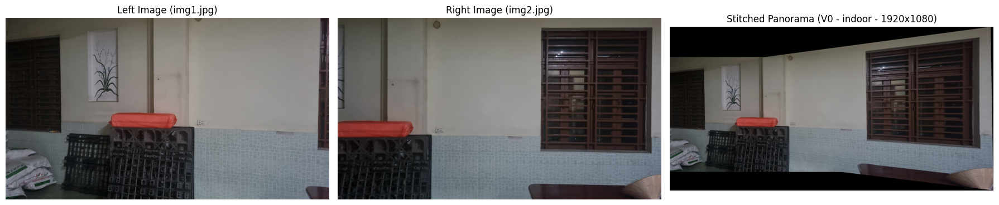

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/indoor/1280x720/img1.jpg (1280 x 720)
Input B    : Dataset_ltss/indoor/1280x720/img2.jpg (1280 x 720)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 220
RANSAC Inliers                : 93
Output Panorama Size          : 2120 x 1105
Estimated Homography H (B -> A):
  [     0.595580      0.052863    422.191791 ]
  [    -0.125052      0.903435     16.188730 ]
  [    -0.000345      0.000055      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |       64.187 |       54.309 |     8.73%
2. Keypoint Detection          |       20.870 |       18.986 |     2.84%
3. Description (rBRIEF)        |       71.927 |       65.073 |     9.79%
4. Feature M

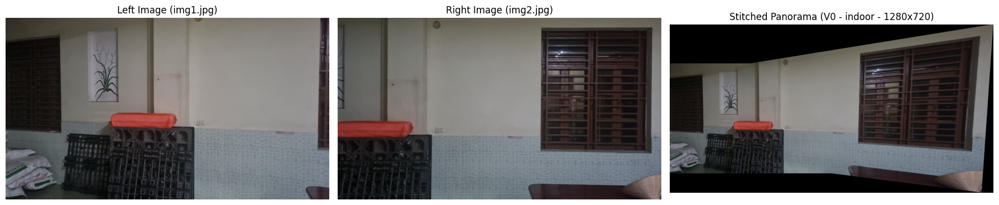

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/outdoor/3840x2160/img1.jpg (3840 x 2160)
Input B    : Dataset_ltss/outdoor/3840x2160/img2.jpg (3840 x 2160)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 132
RANSAC Inliers                : 60
Output Panorama Size          : 6490 x 3418
Estimated Homography H (B -> A):
  [     0.555876      0.022854   1357.671144 ]
  [    -0.109567      0.864199    253.707286 ]
  [    -0.000117     -0.000002      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      576.564 |      503.720 |    29.82%
2. Keypoint Detection          |      260.361 |      250.977 |    13.46%
3. Description (rBRIEF)        |      103.323 |       99.719 |     5.34%
4. Fea

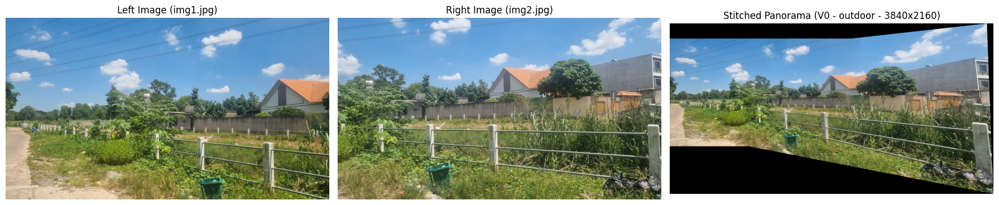

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/outdoor/1920x1080/img1.jpg (1920 x 1080)
Input B    : Dataset_ltss/outdoor/1920x1080/img2.jpg (1920 x 1080)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 161
RANSAC Inliers                : 78
Output Panorama Size          : 3320 x 1742
Estimated Homography H (B -> A):
  [     0.539968      0.006283    685.479412 ]
  [    -0.114775      0.842194    135.528978 ]
  [    -0.000241     -0.000016      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      155.236 |      124.912 |    16.07%
2. Keypoint Detection          |       66.923 |       58.020 |     6.93%
3. Description (rBRIEF)        |       95.372 |       81.795 |     9.88%
4. Fea

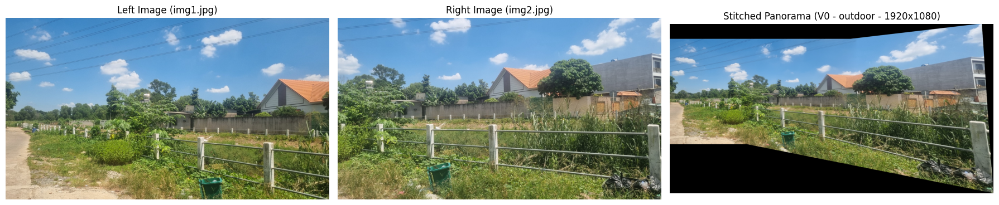

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/outdoor/1280x720/img1.jpg (1280 x 720)
Input B    : Dataset_ltss/outdoor/1280x720/img2.jpg (1280 x 720)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 197
RANSAC Inliers                : 141
Output Panorama Size          : 2236 x 1170
Estimated Homography H (B -> A):
  [     0.524848     -0.014103    464.984432 ]
  [    -0.115822      0.823391     94.282628 ]
  [    -0.000364     -0.000043      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |       57.096 |       55.541 |     8.36%
2. Keypoint Detection          |       29.091 |       27.244 |     4.26%
3. Description (rBRIEF)        |       80.714 |       67.885 |    11.82%
4. Featur

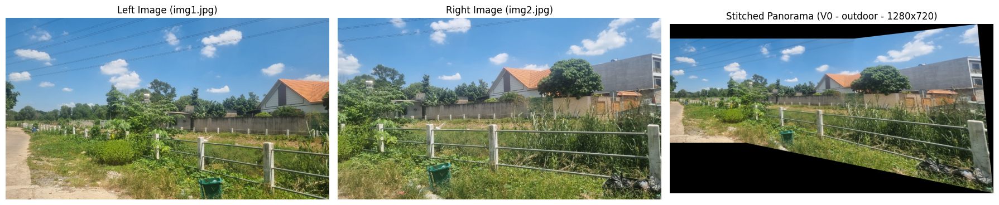

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/other/3840x2160/img1.jpg (3840 x 2160)
Input B    : Dataset_ltss/other/3840x2160/img2.jpg (3840 x 2160)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 174
RANSAC Inliers                : 64
Output Panorama Size          : 7443 x 3590
Estimated Homography H (B -> A):
  [     0.487672     -0.072922   1746.864218 ]
  [    -0.006256      0.858429    -17.478404 ]
  [    -0.000134      0.000014      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      509.513 |      501.578 |    27.45%
2. Keypoint Detection          |      263.338 |      244.106 |    14.19%
3. Description (rBRIEF)        |       93.446 |       78.576 |     5.03%
4. Feature

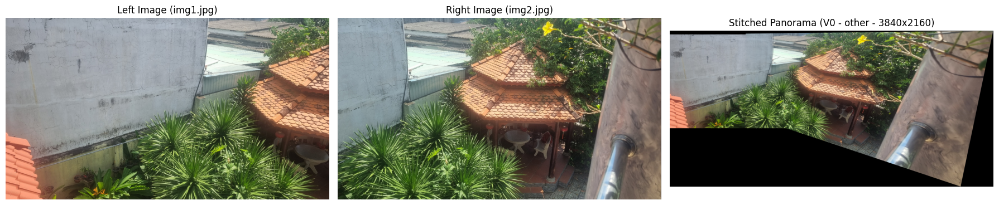

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/other/1920x1080/img1.jpg (1920 x 1080)
Input B    : Dataset_ltss/other/1920x1080/img2.jpg (1920 x 1080)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 264
RANSAC Inliers                : 137
Output Panorama Size          : 3708 x 1799
Estimated Homography H (B -> A):
  [     0.484810     -0.083948    876.043262 ]
  [    -0.006832      0.846587     -4.516976 ]
  [    -0.000267      0.000020      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      145.400 |      125.387 |    15.34%
2. Keypoint Detection          |       69.788 |       58.966 |     7.36%
3. Description (rBRIEF)        |       92.180 |       79.798 |     9.72%
4. Featur

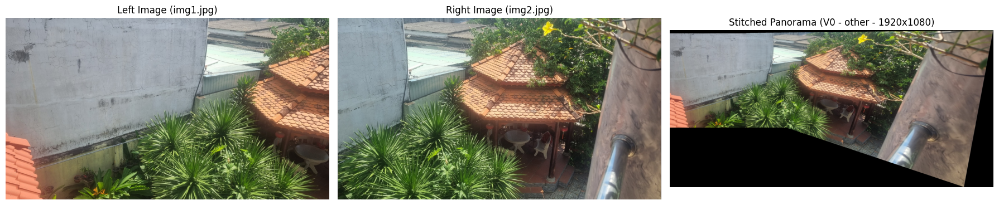

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/other/1280x720/img1.jpg (1280 x 720)
Input B    : Dataset_ltss/other/1280x720/img2.jpg (1280 x 720)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 273
RANSAC Inliers                : 200
Output Panorama Size          : 2541 x 1237
Estimated Homography H (B -> A):
  [     0.464908     -0.070648    586.900819 ]
  [    -0.015609      0.853728     -1.933181 ]
  [    -0.000418      0.000046      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |       57.465 |       54.347 |     8.40%
2. Keypoint Detection          |       28.919 |       27.450 |     4.23%
3. Description (rBRIEF)        |       74.293 |       68.190 |    10.86%
4. Feature Ma

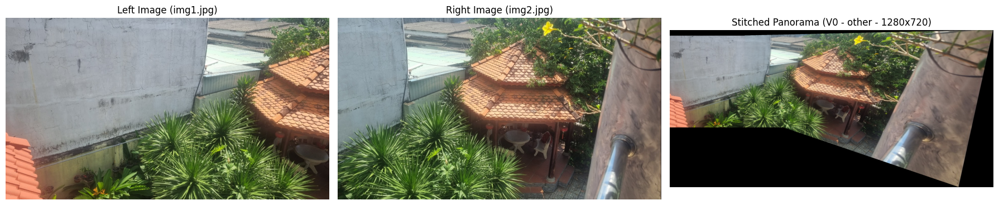

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/challenge/3840x2160/img1.jpg (3840 x 2160)
Input B    : Dataset_ltss/challenge/3840x2160/img2.jpg (3840 x 2160)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 256
RANSAC Inliers                : 193
Output Panorama Size          : 9372 x 4806
Estimated Homography H (B -> A):
  [     0.366203     -0.055648   1979.864913 ]
  [    -0.183103      0.792589    364.009988 ]
  [    -0.000159     -0.000020      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      524.624 |      502.255 |    22.80%
2. Keypoint Detection          |      272.265 |      266.534 |    11.83%
3. Description (rBRIEF)        |       99.107 |       90.600 |     4.31%
4

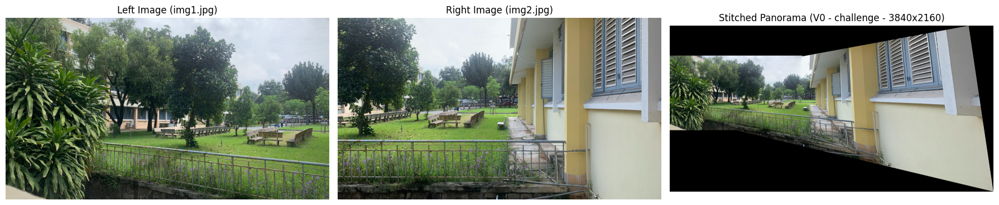

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/challenge/1920x1080/img1.jpg (1920 x 1080)
Input B    : Dataset_ltss/challenge/1920x1080/img2.jpg (1920 x 1080)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 366
RANSAC Inliers                : 318
Output Panorama Size          : 4646 x 2383
Estimated Homography H (B -> A):
  [     0.370065     -0.050149    988.418923 ]
  [    -0.183428      0.797270    181.038421 ]
  [    -0.000316     -0.000036      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |      142.332 |      125.484 |    14.59%
2. Keypoint Detection          |       70.100 |       62.484 |     7.19%
3. Description (rBRIEF)        |       86.701 |       80.127 |     8.89%
4

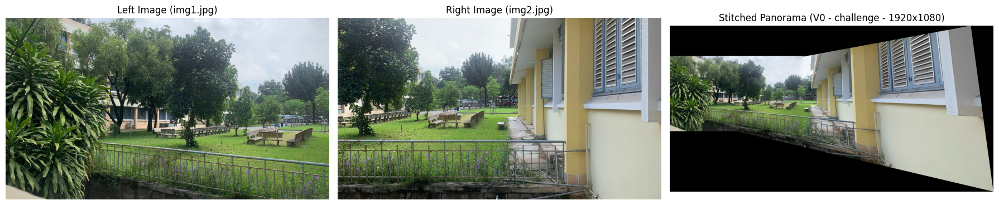

Build Mode : CPU Sequential Build
Input A    : Dataset_ltss/challenge/1280x720/img1.jpg (1280 x 720)
Input B    : Dataset_ltss/challenge/1280x720/img2.jpg (1280 x 720)
Version    : V0 (5 timed runs + 1 warm-up run)

--- Pipeline Statistics ---
Keypoints (Image A / Image B) : 3000 / 3000
Matched Keypoint Pairs        : 363
RANSAC Inliers                : 334
Output Panorama Size          : 3120 x 1601
Estimated Homography H (B -> A):
  [     0.366413     -0.052236    659.275765 ]
  [    -0.182925      0.795126    119.806267 ]
  [    -0.000474     -0.000061      1.000000 ]

--- Stage Timing Breakdown (Average of 5 runs) ---
Stage                          |     Avg (ms) |     Min (ms) | Share (%)
------------------------------------------------------------------------
1. Preprocessing               |       64.712 |       55.236 |     7.93%
2. Keypoint Detection          |       32.158 |       28.938 |     3.94%
3. Description (rBRIEF)        |       90.896 |       76.223 |    11.14%
4. Fe

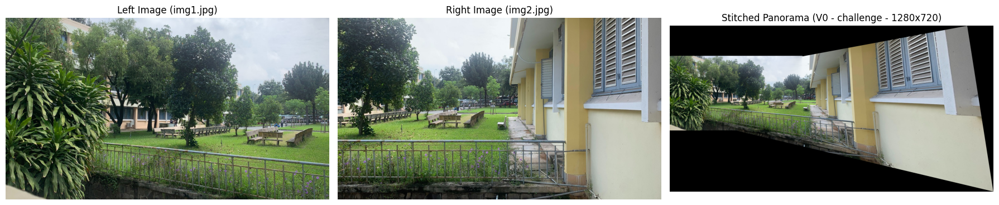

In [5]:
types = [
    "indoor",
    "outdoor",
    "other",
    "challenge"
]
sizes = [
    "3840x2160",
    "1920x1080",
    "1280x720"
]
for type in types:
    type_dir = f"Dataset_ltss/{type}"
    if not os.path.exists(type_dir):
        continue
    for size in sizes:
        size_dir = f"{type_dir}/{size}"
        if not os.path.exists(size_dir) or not os.listdir(size_dir):
            continue

        !./stitch Dataset_ltss/{type}/{size}/img1.jpg \
                Dataset_ltss/{type}/{size}/img2.jpg \
                output/pano_{type}_{size}.png \
                --version 0 --runs 5

        # 3. Hiển thị 2 ảnh gốc và ảnh Panorama kết quả ngay trong Notebook
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        axes[0].imshow(Image.open(f"Dataset_ltss/{type}/{size}/img1.jpg"))
        axes[0].set_title("Left Image (img1.jpg)")
        axes[0].axis("off")

        axes[1].imshow(Image.open(f"Dataset_ltss/{type}/{size}/img2.jpg"))
        axes[1].set_title("Right Image (img2.jpg)")
        axes[1].axis("off")

        axes[2].imshow(Image.open(f"output/pano_{type}_{size}.png"))
        axes[2].set_title(f"Stitched Panorama (V0 - {type} - {size})")
        axes[2].axis("off")

        plt.tight_layout()
        plt.show()

OpenCV version : 5.0.0
[done] indoor     1280x720   goc =     25.58 px (  1.74% duong cheo) | tren inlier OpenCV: median =     2.24 px
[done] indoor     1920x1080  goc =     20.54 px (  0.93% duong cheo) | tren inlier OpenCV: median =     2.16 px
[done] indoor     3840x2160  goc =    607.77 px ( 13.79% duong cheo) | tren inlier OpenCV: median =     5.99 px
[done] outdoor    1280x720   goc =     10.75 px (  0.73% duong cheo) | tren inlier OpenCV: median =     1.41 px
[done] outdoor    1920x1080  goc =     28.63 px (  1.30% duong cheo) | tren inlier OpenCV: median =     2.01 px
[done] outdoor    3840x2160  goc =     78.61 px (  1.78% duong cheo) | tren inlier OpenCV: median =     8.74 px
[done] other      1280x720   goc =     18.42 px (  1.25% duong cheo) | tren inlier OpenCV: median =     1.55 px
[done] other      1920x1080  goc =     50.08 px (  2.27% duong cheo) | tren inlier OpenCV: median =     1.82 px
[done] other      3840x2160  goc =    119.54 px (  2.71% duong cheo) | tren inlie

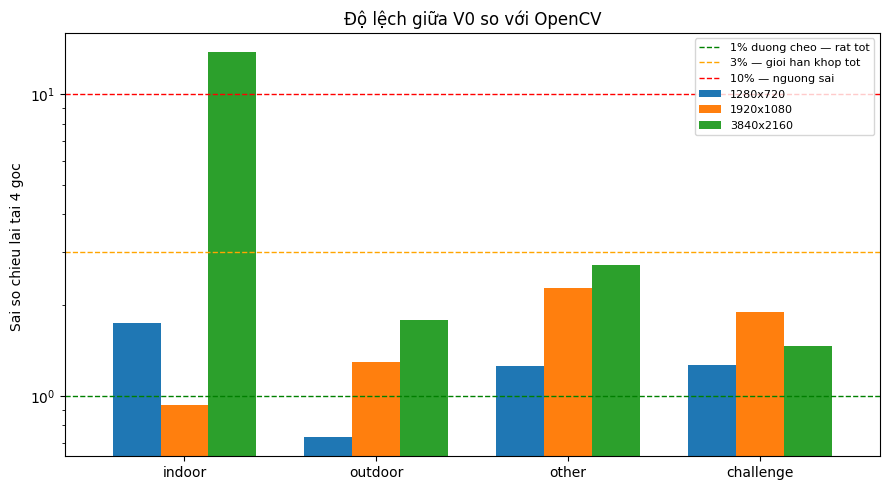

In [8]:
import os, re, subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

print("OpenCV version :", cv2.__version__)
PAIRS = ["indoor", "outdoor", "other", "challenge"]
SIZES = ["1280x720", "1920x1080", "3840x2160"]
H_row_re = re.compile(r"\[\s*(-?\d+\.\d+)\s+(-?\d+\.\d+)\s+(-?\d+\.\d+)\s*\]")

#  V0
def run_v0(pa, pb, out):
    """Chay ./stitch --version 0 va boc tach H, so match, so inlier tu stdout."""
    log = subprocess.run(["./stitch", pa, pb, out, "--version", "0", "--runs", "1"],
                         capture_output=True, text=True).stdout
    rows = H_row_re.findall(log)
    H = np.array(rows[:3], dtype=np.float64) if len(rows) >= 3 else None
    g = lambda pat: (int(m.group(1)) if (m := re.search(pat, log)) else -1)
    return H, g(r"Matched Keypoint Pairs\s*:\s*(\d+)"), g(r"RANSAC Inliers\s*:\s*(\d+)")

MIN_MATCH_COUNT = 10
RATIO = 0.7

def run_opencv(pa, pb):
    imgA = cv2.imread(pa, cv2.IMREAD_GRAYSCALE)
    imgB = cv2.imread(pb, cv2.IMREAD_GRAYSCALE)
    sift = cv2.SIFT_create()
    kpA, desA = sift.detectAndCompute(imgA, None)
    kpB, desB = sift.detectAndCompute(imgB, None)

    flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
    matches = flann.knnMatch(desB, desA, k=2)        # query = B, train = A  -> H: B -> A
    good = [m for m, n in matches if m.distance < RATIO * n.distance]
    if len(good) < MIN_MATCH_COUNT:
        return None, len(good), 0, None, None, (kpA, kpB, good, imgA, imgB, None)

    ptsB = np.float32([kpB[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    ptsA = np.float32([kpA[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(ptsB, ptsA, cv2.RANSAC, 5.0)
    keep = mask.ravel().astype(bool)
    return (H, len(good), int(keep.sum()),
            ptsB[keep].reshape(-1, 2), ptsA[keep].reshape(-1, 2),
            (kpA, kpB, good, imgA, imgB, mask))

# do do sai so
def proj(H, pts):
    """Chieu tap diem (N,2) qua ma tran H."""
    q = np.hstack([pts, np.ones((len(pts), 1))]) @ (H / H[2, 2]).T
    return q[:, :2] / q[:, 2:3]

def corner_err(H1, H2, w, h):
    """Sai so chieu lai tai 4 goc anh B (px) + sai so Frobenius tuong doi."""
    c = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float64)
    e = np.linalg.norm(proj(H1, c) - proj(H2, c), axis=1)
    H1n, H2n = H1 / H1[2, 2], H2 / H2[2, 2]
    return e, np.linalg.norm(H1n - H2n) / np.linalg.norm(H2n)

def point_err(H_v0, ptsB, ptsA):
    """Sai so chieu lai cua H_V0 tren chinh tap inlier cua OpenCV (trong vung chong lap)."""
    return np.linalg.norm(proj(H_v0, ptsB) - ptsA, axis=1)

# nguong danh gia
def verdict_pct(pct):
    """Danh gia theo % duong cheo anh -> doc lap voi do phan giai."""
    if np.isnan(pct):  return "KHONG DO DUOC"
    if pct <  1.0:     return "rat tot (<1% dc)"
    if pct <  3.0:     return "tot (1-3% dc)"
    if pct < 10.0:     return "lech ro (3-10% dc)"
    return "SAI (>10% dc)"

os.makedirs("output", exist_ok=True)
rows = []
for pair in PAIRS:
    for size in SIZES:
        d = f"Dataset_ltss/{pair}/{size}"
        if not os.path.isdir(d):
            continue
        pa, pb = f"{d}/img1.jpg", f"{d}/img2.jpg"
        w, h = Image.open(pb).size
        diag = np.hypot(w, h)

        H_v0, m_v0, in_v0 = run_v0(pa, pb, f"output/verify_{pair}_{size}.png")
        H_cv, m_cv, in_cv, ptsB, ptsA, _ = run_opencv(pa, pb)

        if H_v0 is None or H_cv is None:
            e, rel, ep = np.array([np.nan] * 4), np.nan, np.array([np.nan])
        else:
            e, rel = corner_err(H_v0, H_cv, w, h)
            ep = point_err(H_v0, ptsB, ptsA)

        pct = 100 * e.mean() / diag
        rows.append(dict(pair=pair, size=size,
                         match_V0=m_v0, inlier_V0=in_v0,
                         match_CV=m_cv, inlier_CV=in_cv,
                         err_corner_px=e.mean(), err_pct_diag=pct,
                         err_pts_med=np.median(ep), err_pts_mean=ep.mean(),
                         rel_frobenius=rel, danh_gia=verdict_pct(pct)))
        print(f"[done] {pair:<10} {size:<10} goc = {e.mean():9.2f} px "
              f"({pct:6.2f}% duong cheo) | tren inlier OpenCV: median = {np.median(ep):8.2f} px")

cmp = pd.DataFrame(rows)
pd.set_option("display.width", 220, "display.float_format", lambda v: f"{v:9.3f}")

print("\n=== Doi chieu H cua V0 voi H cua OpenCV (SIFT + FLANN + RANSAC) ===")
print(cmp.to_string(index=False))

print("\n=== So inlier: V0 vs OpenCV (ty le CV/V0) ===")
piv = cmp.pivot_table(index="pair", columns="size", values=["inlier_V0", "inlier_CV"]).reindex(PAIRS)
print(piv)
cmp["ty_le_CV_tren_V0"] = cmp["inlier_CV"] / cmp["inlier_V0"].clip(lower=1)
print(cmp.pivot_table(index="pair", columns="size", values="ty_le_CV_tren_V0").reindex(PAIRS))

# bieu do sai so chuan hoa
fig, ax = plt.subplots(figsize=(9, 5))
cmp.pivot_table(index="pair", columns="size", values="err_pct_diag").reindex(PAIRS)[SIZES].plot(
    kind="bar", ax=ax, width=0.75)
for y, c, lab in [(1, "green", "1% duong cheo — rat tot"),
                  (3, "orange", "3% — gioi han khop tot"),
                  (10, "red", "10% — nguong sai")]:
    ax.axhline(y, ls="--", c=c, lw=1, label=lab)
ax.set_yscale("log")
ax.set_ylabel("Sai so chieu lai tai 4 goc ")
ax.set_xlabel(""); ax.set_title("Độ lệch giữa V0 so với OpenCV")
ax.legend(fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); plt.show()



### **5.2. Correctness**

#### **5.2.1. Phương pháp và cách chọn ngưỡng đánh giá**

Với ảnh chụp thực tế, nhóm không có ground truth tuyệt đối cho ma trận $H$, nên không thể đo sai số theo nghĩa chặt. Cách nhóm chọn là **dùng thuật toán của OpenCV làm thước đo tham chiếu**: bản thân OpenCV cũng chỉ là một ước lượng và cũng có một phần sai số, nhưng đó là một hiện thực đã được cộng đồng kiểm chứng qua nhiều năm, lại dùng bộ thuật toán khác hẳn của nhóm, nên nếu hai bên cho ra gần như cùng một phép biến đổi thì pipeline của nhóm hoạt động đúng.

Quy trình tham chiếu theo đúng tài liệu chính thức *Feature Matching + Homography*
1. Phát hiện và mô tả đặc trưng bằng **SIFT** trên cả hai ảnh.
2. Khớp nối bằng **FLANN** với $k = 2$ láng giềng gần nhất, rồi áp dụng **Lowe's ratio test** ngưỡng $0.7$.
3. Ước lượng $H$ bằng `cv2.findHomography(..., cv2.RANSAC, 5.0)` và lấy mặt nạ inlier mà RANSAC trả về.

Hướng khớp được đặt là query $=$ ảnh B, train $=$ ảnh A, nên $H$ của OpenCV cũng là phép biến đổi $B \to A$ — cùng quy ước với chương trình của nhóm.

**Hai độ đo.** Vì $H$ chỉ xác định tới một hệ số tỉ lệ (homogeneous), so sánh trực tiếp từng phần tử ma trận là vô nghĩa. Nhóm chuẩn hóa cả hai ma trận về $h_{33} = 1$ rồi đo:

- **Sai số chiếu lại tại 4 góc ảnh B** (`err_corner_px`): chiếu 4 góc của ảnh B bằng $H_{V0}$ và bằng $H_{OpenCV}$, đo khoảng cách Euclid giữa hai kết quả. Đây là độ đo khắt khe nhất vì bốn góc là vùng xa tâm nhất.
- **Sai số chiếu lại trên chính tập inlier của OpenCV** (`err_pts_med`, `err_pts_mean`): lấy các cặp điểm $(p_B, p_A)$ mà RANSAC của OpenCV giữ lại, rồi đo $\lVert H_{V0} \, p_B - p_A \rVert$. Độ đo này nằm **bên trong vùng chồng lấp**, tại các vị trí đặc trưng thật, nên phản ánh đúng mức lệch mà người xem cảm nhận trên panorama.

Kèm theo là **sai số Frobenius tương đối** giữa hai ma trận sau chuẩn hóa, để thấy mức khác biệt trên bản thân ma trận.

**Ngưỡng nhóm dùng.** Sai số tại góc được quy về **phần trăm đường chéo ảnh B** ($1468.6$ px ở 720p, $2202.9$ px ở 1080p, $4405.8$ px ở 4K) nên thang đo độc lập với độ phân giải:

| `err_pct_diag` | Diễn giải |
| :--- | :--- |
| $< 1\%$ | Khớp rất tốt — hai phương pháp đồng thuận |
| $1\% - 3\%$ | Khớp tốt — panorama liền mạch bằng mắt thường |
| $3\% - 10\%$ | Lệch rõ — cần soát lại tham số Stage 4 |
| $> 10\%$ | Sai — pipeline đã chọn sai tập inlier |




#### **5.2.2. Kết quả đối chiếu và chẩn đoán**

Số liệu lấy từ ô output ngay trên:

| Cặp ảnh | Độ phân giải | Match V0 | Inlier V0 | Match CV | Inlier CV | Tỉ lệ CV/V0 | Sai số góc (px) | **% đường chéo** | Median trên inlier (px) | Frobenius | Đánh giá |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | :--- |
| indoor | 1280×720 | 220 | 93 | 62 | 54 | 0.58× | 25.58 | **1.74%** | 2.24 | 0.021 | Tốt |
| indoor | 1920×1080 | 192 | 48 | 68 | 43 | 0.90× | 20.54 | **0.93%** | 2.16 | 0.012 | Rất tốt |
| indoor | 3840×2160 | 109 | **8** | 68 | 25 | 3.13× | 607.77 | **13.80%** | 5.99 | 0.010 | **SAI** |
| outdoor | 1280×720 | 197 | 141 | 597 | 511 | 3.62× | 10.75 | **0.73%** | 1.42 | 0.003 | Rất tốt |
| outdoor | 1920×1080 | 161 | 78 | 1430 | 1084 | 13.90× | 28.63 | **1.30%** | 2.01 | 0.016 | Tốt |
| outdoor | 3840×2160 | 132 | 60 | 4510 | 2960 | 49.33× | 78.61 | **1.78%** | 8.74 | 0.048 | Tốt |
| other | 1280×720 | 273 | 200 | 726 | 653 | 3.27× | 18.42 | **1.25%** | 1.55 | 0.005 | Tốt |
| other | 1920×1080 | 264 | 137 | 1162 | 798 | 5.83× | 50.08 | **2.27%** | 1.82 | 0.007 | Tốt |
| other | 3840×2160 | 174 | 64 | 3507 | 1798 | 28.09× | 119.54 | **2.71%** | 4.29 | 0.011 | Tốt |
| challenge | 1280×720 | 363 | 334 | 968 | 940 | 2.81× | 18.61 | **1.27%** | 1.23 | 0.003 | Tốt |
| challenge | 1920×1080 | 366 | 318 | 1754 | 1518 | 4.77× | 41.75 | **1.90%** | 1.21 | 0.002 | Tốt |
| challenge | 3840×2160 | 256 | 193 | 4869 | 3912 | 20.27× | 64.47 | **1.46%** | 3.07 | 0.002 | Tốt |



### **5.3. Bảng thời gian từng stage ở cả ba độ phân giải**

| Cặp ảnh | Độ phân giải | S1 Tiền xử lý | S2 Phát hiện | S3 Mô tả | S4 Khớp nối | S5 RANSAC | S6 Warp & Blend | **Tổng** |
| :--- | :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| indoor | 1280×720 | 64.19 | 20.87 | 71.93 | 517.05 | 4.11 | 56.90 | **735.05** |
| indoor | 1920×1080 | 124.69 | 42.24 | 77.56 | 453.10 | 3.36 | 109.97 | **810.91** |
| indoor | 3840×2160 | 576.71 | 177.80 | 79.75 | 448.63 | 2.49 | 644.87 | **1930.24** |
| outdoor | 1280×720 | 57.10 | 29.09 | 80.71 | 453.60 | 4.38 | 57.79 | **682.67** |
| outdoor | 1920×1080 | 155.24 | 66.92 | 95.37 | 500.77 | 3.54 | 143.91 | **965.75** |
| outdoor | 3840×2160 | 576.56 | 260.36 | 103.32 | 447.71 | 3.05 | 542.79 | **1933.80** |
| other | 1280×720 | 57.47 | 28.92 | 74.29 | 451.82 | 6.77 | 65.13 | **684.40** |
| other | 1920×1080 | 145.40 | 69.79 | 92.18 | 488.84 | 5.09 | 146.64 | **947.94** |
| other | 3840×2160 | 509.51 | 263.34 | 93.45 | 446.51 | 3.41 | 539.96 | **1856.18** |
| challenge | 1280×720 | 64.71 | 32.16 | 90.90 | 507.90 | 9.09 | 111.05 | **815.80** |
| challenge | 1920×1080 | 142.33 | 70.10 | 86.70 | 456.08 | 8.72 | 211.70 | **975.63** |
| challenge | 3840×2160 | 524.62 | 272.27 | 99.11 | 448.19 | 6.27 | 950.85 | **2301.31** |

**Trung bình trên 4 cặp ảnh — thời gian (ms) và tỷ trọng (%)**

| Stage | Small 720p (ms) | Small (%) | Medium 1080p (ms) | Medium (%) | Large 4K (ms) | Large (%) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| 1. Tiền xử lý | 60.9 | 8.36 | 141.9 | 15.35 | 546.9 | **27.49** |
| 2. Phát hiện keypoint | 27.8 | 3.82 | 62.3 | 6.67 | 243.4 | 12.17 |
| 3. Mô tả rBRIEF | 79.5 | 10.90 | 88.0 | 9.51 | 93.9 | 4.70 |
| 4. Khớp nối đặc trưng | 482.6 | **66.26** | 474.7 | **51.51** | 447.8 | 22.48 |
| 5. Homography (RANSAC) | 6.1 | 0.83 | 5.2 | 0.55 | 3.8 | 0.18 |
| 6. Warp & Blending | 72.7 | 9.84 | 153.1 | 16.41 | 669.6 | **32.97** |
| **Tổng** | **729.5** | 100 | **925.1** | 100 | **2005.4** | 100 |

Ô code bên dưới vẽ lại ba biểu đồ từ đúng bảng số liệu này.

### **5.4. Hot stage**

Thứ tự các stage "nóng" **thay đổi theo độ phân giải**.

**a) Ở 720p và 1080p: Stage 4 (Khớp nối đặc trưng) là điểm nghẽn tuyệt đối — chiếm 66.26% và 51.51%.**

Nguyên nhân nằm ở độ phức tạp thuật toán, không ở kích thước ảnh. Nhóm cố định $K = 3000$ keypoint mỗi ảnh, nên brute-force matching luôn phải tính đủ $3000 \times 3000 = 9 \times 10^6$ khoảng cách Hamming, mỗi khoảng cách gồm 8 phép XOR + `popcount` trên `uint32_t`; thêm tầng cross-check phải quét hai chiều nên tổng khoảng $1.8 \times 10^7$ lần so sánh descriptor. Chi phí này **độc lập với số pixel**, và số liệu xác nhận rất rõ: Stage 4 chỉ dao động $446.5$ - $517.1$ ms (trung bình $468.3$ ms) trên **toàn bộ 12 cấu hình**, tức gần như một hằng số. Tỷ trọng của nó tụt từ $66.26\%$ xuống $22.48\%$ khi lên 4K không phải vì nó nhanh hơn, mà vì các stage khác phình ra.

**b) Ở 4K: Stage 6 và Stage 1 cùng chiếm ưu thế — 32.97% và 27.49%, tổng cộng 60.46%.**

Hai stage này duyệt theo pixel nên chi phí tỷ lệ thuận với diện tích ảnh (Stage 1) và diện tích panorama đầu ra (Stage 6). Kiểm chứng quy luật co giãn của Stage 1: số pixel tăng $2.25\times$ (0.92 → 2.07 MP) rồi $4\times$ (2.07 → 8.29 MP), và thời gian tăng tương ứng — `outdoor`: $57.10 \to 155.24 \to 576.56$ ms (hệ số $2.72\times$ rồi $3.71\times$); `other`: $57.47 \to 145.40 \to 509.51$ ms ($2.53\times$ rồi $3.50\times$). Đúng **$O(N_{pixel})$ tuyến tính** như kỳ vọng với một bộ lọc stencil $5 \times 5$.

Stage 6 co giãn mạnh hơn cả Stage 1 vì panorama đầu ra lớn hơn ảnh vào: cặp `challenge` ở 4K cho panorama $9372 \times 4806 \approx 45$ MP, gấp $5.4$ lần ảnh đầu vào, và thời gian Stage 6 lên tới $950.85$ ms — **stage đắt nhất trong toàn bộ 12 cấu hình**. Mỗi pixel đầu ra phải nhân với $H^{-1}$, nội suy song tuyến tính trên hai ảnh rồi hòa trộn theo trọng số feathering.

**c) Stage 5 (RANSAC) không đáng kể: 0.13% - 1.11%.**

RANSAC chỉ làm việc trên $109$ - $366$ cặp khớp đã lọc, nên dù chạy hàng nghìn vòng lặp thì khối lượng tính toán vẫn nhỏ hơn hai bậc so với các stage duyệt pixel. Thời gian của nó thậm chí **giảm** khi độ phân giải tăng ($6.1 \to 5.2 \to 3.8$ ms trung bình) vì số cặp khớp giảm theo (xem kết luận 5 ở mục 5.1.2). Hệ quả trực tiếp: **đưa Stage 5 lên GPU gần như không cải thiện thời gian** — lý do duy nhất để làm vậy ở V3 là loại bỏ điểm đồng bộ host-device ở giữa pipeline.

**d) Stage 3 (rBRIEF) gần như hằng số: $71.9$ - $103.3$ ms**, vì chi phí phụ thuộc $K$ chứ không phụ thuộc số pixel — mỗi keypoint chỉ đọc một vùng vá $31 \times 31$ và so sánh 256 cặp điểm, tổng $3000 \times 256$ phép so sánh mỗi ảnh. Stage 2 thì vẫn co giãn theo pixel ($27.8 \to 62.3 \to 243.4$ ms) vì phần tính Harris response và NMS chạy trên toàn ảnh.

**e) Tóm tắt định hướng tối ưu.** Hai stage cần ưu tiên là **Stage 4** (nghẽn ở 720p/1080p, và tốn nhiều thời gian tuyệt đối nhất tính trung bình) và **Stage 6** (nghẽn ở 4K, với đỉnh $950.85$ ms). Stage 1 xếp ngay sau. Ba stage này cộng lại chiếm $84.46\%$ thời gian ở 720p, $83.27\%$ ở 1080p và $82.94\%$ ở 4K — nghĩa là dù ở độ phân giải nào, tối ưu đúng ba stage này là đủ để quyết định hiệu năng toàn chương trình. Điều may mắn là cả ba đều thuộc những mẫu hình song song quen thuộc: stencil (Stage 1), all-pairs kiểu nhân ma trận (Stage 4) và gather theo pixel (Stage 6).

### **5.5. Amdahl estimate**

Nếu phần công việc song song hóa được chiếm tỉ lệ $p$ trong tổng thời gian của phiên bản tuần tự, thì dù phần đó được tăng tốc bao nhiêu lần, tốc độ toàn chương trình cũng không vượt quá:

$$S_{max} = \lim_{s \to \infty} \frac{1}{(1 - p) + \dfrac{p}{s}} = \frac{1}{1 - p}$$

**Kế hoạch của nhóm: đưa 5 stage (1, 2, 3, 4, 6) lên GPU, giữ Stage 5 (RANSAC) trên CPU ở V1.** Khi đó $p$ là tổng tỷ trọng của 5 stage đó và $1 - p$ là tỷ trọng của Stage 5. Giá trị $p$ cùng giới hạn $S_{max}$ được chương trình in trực tiếp trong mỗi lần chạy ở mục 5.2:

| Cặp ảnh | Độ phân giải | $1 - p$ (Stage 5) | $p$ | $S_{max} = 1/(1-p)$ |
| :--- | :--- | ---: | ---: | ---: |
| indoor | 1280×720 | 0.0056 | 0.9944 | 178.84× |
| indoor | 1920×1080 | 0.0041 | 0.9959 | 241.22× |
| indoor | 3840×2160 | 0.0013 | 0.9987 | 776.08× |
| outdoor | 1280×720 | 0.0064 | 0.9936 | 155.77× |
| outdoor | 1920×1080 | 0.0037 | 0.9963 | 272.61× |
| outdoor | 3840×2160 | 0.0016 | 0.9984 | 632.99× |
| other | 1280×720 | 0.0099 | 0.9901 | 101.04× |
| other | 1920×1080 | 0.0054 | 0.9946 | 186.13× |
| other | 3840×2160 | 0.0018 | 0.9982 | 543.26× |
| challenge | 1280×720 | 0.0111 | 0.9889 | **89.77×** |
| challenge | 1920×1080 | 0.0089 | 0.9911 | 111.92× |
| challenge | 3840×2160 | 0.0027 | 0.9973 | 367.16× |

**Cách đọc bảng này cho đúng.** Trường hợp bất lợi nhất là `challenge` ở 720p: $p = 0.9889 \Rightarrow S_{max} = 89.77\times$. Thuận lợi nhất là `indoor` ở 4K: $p = 0.9987 \Rightarrow S_{max} = 776.08\times$. Có thể thấy $p$ **tăng theo độ phân giải** ở mọi cặp ảnh, vì Stage 5 giữ nguyên chi phí trong khi các stage song song hóa được thì phình ra — nghĩa là càng lên kích thước lớn, trần Amdahl càng cao.

Nói cách khác, **với kế hoạch song song hóa 5/6 stage, định luật Amdahl không phải yếu tố giới hạn thực tế của đồ án này**: ngưỡng $90\times$ - $776\times$ cao hơn rất nhiều mức tăng tốc mà một GPU Colab (T4 / L4) có thể đạt trên bài toán này. Giới hạn thật sự đến từ những yếu tố **không nằm trong mô hình Amdahl**:

1. **Thời gian truyền dữ liệu host ↔ device.** Một ảnh 4K RGB là $\approx 24$ MB; truyền hai ảnh vào và một panorama lên tới $45$ MP ra qua PCIe tốn hàng chục ms — chi phí **mới phát sinh**, không tồn tại trong V0 và không được Amdahl tính đến. Vì vậy nhóm sẽ giữ toàn bộ dữ liệu trung gian trên GPU giữa các stage thay vì copy về sau mỗi stage.
2. **Chi phí khởi tạo CUDA context và launch overhead** mỗi kernel. Với Stage 5 còn ở CPU, V1 phải đồng bộ và copy danh sách match về host rồi copy $H$ trở lại — một điểm đồng bộ cứng ở giữa pipeline.
3. **Mức tăng tốc thực tế của từng kernel**, phụ thuộc băng thông bộ nhớ và occupancy, chứ không phải $s \to \infty$ như công thức lý tưởng. Stage 1 và Stage 6 đều bị giới hạn bởi băng thông, nên mức tăng tốc của chúng sẽ xấp xỉ tỉ số băng thông bộ nhớ GPU/CPU chứ không theo số lõi.

Vì vậy nhóm **không đặt mục tiêu theo con số Amdahl**, mà đặt mục tiêu theo bản chất tính toán của từng stage: Stage 4 (bài toán all-pairs, cấu trúc giống nhân ma trận, rất phù hợp tiling trên shared memory) kỳ vọng tăng tốc cao nhất; Stage 1 và Stage 6 kỳ vọng tăng tốc xấp xỉ tỉ số băng thông.

Một ghi chú về output: dòng *"Parallelizable fraction (All 6 Stages): p = 0.9999 → Max Speedup = 10000.00x"* chỉ là giá trị bị chặn trên của biểu thức khi $1 - p \to 0$ (nếu song song hóa cả 6 stage thì theo mô hình lý tưởng $p = 1$ và $S_{max}$ phân kỳ về vô cực). Con số $10000\times$ này **không có ý nghĩa vật lý**; nhóm không dùng nó làm mục tiêu và chỉ báo cáo cột $p$ của 5 stage trong bảng trên.

## **6. Bộ Dữ Liệu Của Nhóm (Dataset)**



### **6.1. Quy tắc thu thập dữ liệu**

Toàn bộ ảnh do nhóm tự chụp tại các địa điểm khác nhau, tuân thủ hai nguyên tắc:

- **Xoay máy, không di chuyển chỗ đứng.** Người chụp đứng cố định một vị trí và chỉ xoay máy quanh trục giữa hai lần bấm máy.
- **Độ chồng lấp 30% - 50%** giữa hai ảnh.

Mỗi cặp ảnh sau khi chụp được **cắt về đúng tỉ lệ 16:9** rồi xuất ra **ba độ phân giải** từ cùng một ảnh gốc:

| Bộ | Độ phân giải | Số pixel | Mục đích |
| :--- | :--- | ---: | :--- |
| Small | 1280×720 | 0.92 MP | Phát triển và gỡ lỗi nhanh |
| Medium | 1920×1080 | 2.07 MP | Mốc benchmark chính cho bảng speedup |
| Large | 3840×2160 | 8.29 MP | Thể hiện khả năng co giãn của GPU; V0 mất vài giây |




### **6.2. Danh sách các site đã đăng ký**

Nhóm chuẩn bị **4 cặp ảnh**: 3 cặp chuẩn và 1 cặp challenging.
| Mã site | Loại cảnh | Mô tả nội dung cảnh | Số cặp |
| :--- | :--- |  :--- | :---: |
| `indoor` | Trong nhà |  Cảnh nội thất trong nhà | 1 |
| `outdoor` | Ngoài trời | Cảnh ngoài trời | 1 |
| `other` | Tự chọn | Chụp ảnh cây từ trên xuống | 1 |
| `challenge` | Khó | Gồm nhiều hàng rào khó phân biệt | 1 |




### **6.3. Cấu trúc thư mục và dữ liệu**

Dataset: https://drive.google.com/drive/folders/1I9BgEL_8Cngj2Z8MjeMReCGUq0ppzxUS?usp=drive_link

```
Dataset_ltss/
├── indoor/
│   ├── 1280x720/   { img1.jpg, img2.jpg }
│   ├── 1920x1080/  { img1.jpg, img2.jpg }
│   └── 3840x2160/  { img1.jpg, img2.jpg }
├── outdoor/        
├── other/          
└── challenge/     
```

## **7. Kế Hoạch Hiện Thực Trên GPU**

### **7.1. Những stage sẽ đưa lên GPU và lý do**

| Stage | Tỷ trọng (Small → Large) | Quyết định | Lý do dựa trên profiling |
| :--- | :--- | :--- | :--- |
| **1. Tiền xử lý** | 8.4% → 27.5% | **Lên GPU (V1)** | Tỷ trọng tăng mạnh theo độ phân giải và đã chiếm hơn 1/4 thời gian ở 4K. Bản chất là stencil $5\times5$ đồng nhất, mỗi pixel đầu ra độc lập — dạng bài toán lý tưởng cho mô hình 1 thread/pixel. |
| **2. Phát hiện keypoint** | 3.8% → 12.2% | **Lên GPU (V1)** | Cũng co giãn tuyến tính theo số pixel. Phần tính Harris response và NMS hoàn toàn song song theo pixel; chỉ bước gom keypoint và chọn Top-$K$ cần xử lý đặc biệt. |
| **3. Mô tả rBRIEF** | 10.9% → 4.7% | **Lên GPU (V1)** | Tuy không phải điểm nghẽn lớn nhất, nhưng dữ liệu đầu vào (ảnh đã blur) và đầu ra (descriptor) đều đã nằm trên GPU từ Stage 2. Giữ stage này ở CPU sẽ buộc phải copy ảnh về host rồi copy descriptor lên device — chi phí truyền còn lớn hơn chính phép tính. |
| **4. Khớp nối đặc trưng** | **66.3% → 22.5%** | **Lên GPU (V1) — ưu tiên số 1** | Điểm nghẽn tuyệt đối ở 720p/1080p và tốn thời gian lớn nhất theo giá trị tuyệt đối gần như không đổi ($446.5$ - $517.1$ ms, trung bình $468.3$ ms) ở mọi độ phân giải. Đây là bài toán all-pairs $N_A \times N_B$, cấu trúc giống nhân ma trận nên tiling trên shared memory cho hiệu quả cao; `__popc` tính Hamming trong một lệnh phần cứng duy nhất. |
| **5. Homography (RANSAC)** | 0.8% → 0.2% | **Giữ ở CPU trong V1, chuyển lên GPU ở V3** | Chi phí không đáng kể nên tăng tốc nó gần như không cải thiện tổng thời gian (xem Amdahl ở 5.5). Lý do duy nhất để chuyển lên GPU ở V3 là **loại bỏ điểm đồng bộ host-device ở giữa pipeline**, giúp toàn bộ dữ liệu nằm liên tục trên GPU. |
| **6. Warp & Blending** | 9.8% → **33.0%** | **Lên GPU (V1) — ưu tiên số 2** | Stage nặng nhất ở 4K (đỉnh $950.85$ ms ở cặp `challenge`). Là bài toán gather hoàn hảo: mỗi pixel đầu ra độc lập, chỉ đọc vài pixel đầu vào. Texture memory còn cung cấp nội suy song tuyến tính bằng phần cứng. |

**Kết luận:** V1 đưa 5 stage (1, 2, 3, 4, 6) lên GPU, tương ứng $p = 0.989 - 0.999$ và giới hạn Amdahl $89.77\times - 776.08\times$ (mục 5.5). Hai stage được ưu tiên tối ưu sâu nhất ở V2 - V4 là **Stage 4** (nghẽn ở kích thước nhỏ và trung bình) và **Stage 6** (nghẽn ở kích thước lớn), đúng với bảng phân công ở mục 1.2. Cùng với Stage 1, ba stage này chiếm $82.9\%$ - $84.5\%$ tổng thời gian ở mọi độ phân giải (mục 5.4e), nên chúng quyết định hiệu năng của toàn chương trình.

### **7.2. Thiết kế thread mapping cho V1**

V1 dùng các kernel đơn giản nhất, chỉ dùng global memory, để làm mốc đo cho các tối ưu về sau. Với mỗi stage, nhóm xác định rõ **một thread tính ra cái gì**:

| Stage | Đơn vị công việc của 1 thread | Cấu hình grid / block | Ghi chú thiết kế |
| :--- | :--- | :--- | :--- |
| 1a. Grayscale | 1 pixel đầu ra: đọc 3 byte RGB, ghi 1 `float` | Block $16 \times 16$; grid $\lceil W/16 \rceil \times \lceil H/16 \rceil$ | Hoàn toàn element-wise, không phụ thuộc lân cận. |
| 1b. Gaussian blur 2D | 1 pixel đầu ra: đọc $5 \times 5 = 25$ pixel lân cận từ global memory, nhân với trọng số, ghi 1 `float` | Block $16 \times 16$ (2D) | V1 cố ý **không** dùng shared memory: mỗi pixel bị đọc lại tới 25 lần, tạo ra điểm nghẽn băng thông mà V2 sẽ khắc phục. |
| 2a. Harris response | 1 pixel: tính $I_x, I_y$ bằng Sobel, tích lũy $M = \sum w \cdot [I_x^2, I_x I_y; I_x I_y, I_y^2]$ trong cửa sổ, ghi $R = \det M - k\,(\text{tr}\,M)^2$ | Block $16 \times 16$ | Ghi ra mảng response cùng kích thước ảnh. |
| 2b. NMS | 1 pixel: so sánh $R$ của mình với $5 \times 5$ lân cận, nếu là cực đại địa phương và $R >$ ngưỡng thì ghi keypoint | Block $16 \times 16$ | Số keypoint sinh ra là **biến động**, nên V1 dùng `atomicAdd` trên một biến đếm toàn cục để lấy chỗ ghi — đơn giản nhưng gây tranh chấp (contention); V3 sẽ thay bằng prefix-sum compaction. |
| 2c. Top-$K$ | — | Thực hiện trên CPU ở V1 | Sắp xếp vài nghìn phần tử; V3 sẽ hiện thực parallel selection trên GPU. |
| 3. rBRIEF | **1 thread / keypoint**: tính hướng bằng intensity centroid trên vùng vá $31 \times 31$, quay 256 cặp điểm mẫu theo góc đó, so sánh cường độ và đóng gói thành 8 `uint32_t` | Block 256 thread (1D); grid $\lceil K/256 \rceil$ | V1 đọc 256 cặp điểm mẫu từ global memory; V2 chuyển sang `__constant__` memory vì mọi thread đọc **cùng** dữ liệu này (broadcast). |
| 4. Matching | **1 thread / keypoint của ảnh A**: quét tuần tự toàn bộ $N_B$ descriptor của ảnh B, giữ lại khoảng cách nhỏ nhất $d_1$ và nhỏ nhì $d_2$, áp dụng ratio test | Block 256 thread (1D); grid $\lceil N_A/256 \rceil$ | Dùng `__popc` thay cho `__builtin_popcount`. Chạy kernel hai lần theo hai chiều (A→B và B→A) để thực hiện cross-check. Toàn bộ descriptor của B được đọc từ global memory bởi **mọi** thread — đây chính là điểm nghẽn mà V3 giải quyết bằng tiled matching trên shared memory. |
| 5. RANSAC | — | CPU (V1) | Copy danh sách match về host, tính $H$, copy $H$ (9 `float`) lên device. |
| 6. Warp & Blend | **1 thread / pixel của panorama đầu ra**: nhân toạ độ với $H^{-1}$, kiểm tra có nằm trong ảnh B không, nội suy song tuyến tính, hòa trộn với ảnh A theo trọng số feathering | Block $16 \times 16$; grid theo kích thước panorama | Mô hình gather: mỗi thread chỉ **đọc** từ hai ảnh nguồn và **ghi** đúng một pixel, không cần nguyên tử hóa. |

Nguyên tắc: **dữ liệu ảnh được nạp lên GPU một lần duy nhất ở đầu pipeline và giữ nguyên trên đó**; giữa các stage chỉ truyền con trỏ device, không copy về host (ngoại lệ duy nhất là điểm đồng bộ của Stage 5).

### **7.3. Các ý tưởng tối ưu dự kiến cho V2 - V4**
**Ý tưởng 1 - V2: Khai thác phân cấp bộ nhớ (shared memory, constant memory, separable filter).**
- *Điểm nghẽn nhắm tới:* Stage 1 chiếm 24% thời gian ở 4K và trong V1 mỗi pixel bị đọc lại 25 lần từ global memory — kernel bị giới hạn bởi băng thông, không phải bởi năng lực tính toán.
- *Cách làm:* (a) tách bộ lọc Gaussian $5 \times 5$ thành hai lần quét 1D, giảm số phép nhân từ $k^2 = 25$ xuống $2k = 10$ mỗi pixel; (b) nạp tile ảnh kèm viền halo vào shared memory để mỗi pixel chỉ đọc từ global memory một lần; (c) đưa 256 cặp điểm mẫu BRIEF vào `__constant__` memory để hưởng cơ chế broadcast; (d) bảo đảm truy cập coalesced ở Stage 6.
- *Kỳ vọng:* giảm đáng kể thời gian Stage 1 và Stage 3; tác động rõ nhất ở độ phân giải 4K.

**Ý tưởng 2 - V3: Tối ưu ở mức warp và thay đổi mẫu hình song song (tiled matching, `__popc`, prefix-sum compaction, warp-shuffle reduction).**
- *Điểm nghẽn nhắm tới:* Stage 4 — vẫn là stage tốn nhiều thời gian tuyệt đối nhất và trong V1 mọi thread đều đọc lại toàn bộ $N_B$ descriptor từ global memory (tổng lưu lượng đọc $\approx N_A \times N_B \times 32$ byte).
- *Cách làm:* (a) tiling descriptor của ảnh B vào shared memory theo từng khối, mỗi khối thread cùng dùng — hoàn toàn tương tự tiled matrix multiplication; (b) thay `atomicAdd` gom keypoint ở Stage 2 bằng stream compaction dựa trên prefix sum; (c) song song hóa RANSAC với mô hình **một warp xử lý một giả thuyết**, dùng `__shfl_down_sync` để đếm inlier bằng warp-level reduction thay vì nguyên tử hóa.
- *Kỳ vọng:* đây là phiên bản nhóm kỳ vọng cho mức tăng tốc lớn nhất, đặc biệt ở 720p/1080p nơi Stage 4 chiếm trên 50% thời gian.

**Ý tưởng 3 - V4: Tối ưu ở mức pipeline (texture memory, kernel fusion, CUDA streams, early termination).**
- *Điểm nghẽn nhắm tới:* sau khi V2 và V3 đã rút ngắn các kernel, phần chi phí còn lại dồn về truyền dữ liệu, launch overhead và Stage 6 ở 4K.
- *Cách làm:* (a) đưa hai ảnh nguồn của Stage 6 vào texture memory để dùng nội suy song tuyến tính bằng phần cứng; (b) hợp nhất kernel grayscale và blur thành một để tiết kiệm một lượt đọc/ghi toàn ảnh; (c) dùng hai CUDA stream xử lý đồng thời ảnh A và ảnh B ở Stage 1-3 (các stage này độc lập dữ liệu, như đã nêu ở mục 2.2) kết hợp pinned memory để chồng lấp truyền dữ liệu với tính toán; (d) early termination trong matching và RANSAC.
- *Kỳ vọng:* mức cải thiện nhỏ hơn hai phiên bản trước nhưng rõ rệt ở 4K, nơi chi phí truyền dữ liệu lớn nhất.

### **7.4. Những rủi ro nhóm dự báo**

1. **Rủi ro lớn nhất - tính nhất quán kết quả so với V0.** Thứ tự cộng dồn dấu phẩy động trên GPU khác với CPU (ví dụ khi tích lũy ma trận Harris hoặc rút gọn song song), nên giá trị response có thể lệch ở những chữ số cuối. Với các pixel có response sát ngưỡng NMS, sai lệch nhỏ này đủ để **đổi hẳn tập keypoint**, kéo theo đổi tập match và đổi ma trận $H$ — khi đó panorama sẽ khác V0 dù không có lỗi logic nào. *Biện pháp:* so sánh kết quả theo nhiều mức (ảnh xám và ảnh blur so bằng sai số tuyệt đối tối đa; keypoint so theo khoảng cách toạ độ; cuối cùng so sai số chiếu lại của $H$ trên cặp ảnh tổng hợp ở mục 5.2) thay vì đòi hai panorama trùng nhau từng bit.

2. **Tranh chấp nguyên tử và tính bất định của thứ tự.** `atomicAdd` khi gom keypoint ở V1 khiến **thứ tự** keypoint trong mảng kết quả phụ thuộc vào thứ tự thực thi của các block, tức là thay đổi giữa các lần chạy. Nếu Top-$K$ hoặc RANSAC phụ thuộc vào thứ tự này thì kết quả sẽ không tái lập được. *Biện pháp:* sắp xếp keypoint theo một khoá tất định (ví dụ chỉ số pixel) ngay sau khi gom, và cố định seed cho RANSAC.

3. **Warp divergence và tải không đều ở Stage 6.** Với panorama lớn, nhiều thread rơi vào vùng ngoài biên ảnh B và kết thúc sớm, trong khi các thread cùng warp ở vùng chồng lấp phải nội suy và hòa trộn đầy đủ — gây mất hiệu suất ở các warp nằm trên đường biên vùng chồng lấp.

4. **Giới hạn bộ nhớ GPU ở độ phân giải 4K.** Panorama của cặp `challenge` ở 4K có kích thước $9372 \times 4806 \approx 45$ MP; lưu dạng `float` 3 kênh sẽ tốn $\approx 540$ MB, cộng thêm ảnh nguồn và các mảng trung gian. Trên GPU Colab (T4 16 GB) vẫn đủ, nhưng cần tính toán cẩn thận và cân nhắc lưu đầu ra dạng `uint8` ngay trên device.

5. **Tính so sánh được của bảng benchmark.** Đề bài yêu cầu mọi phiên bản trong một bảng so sánh phải đo trên **cùng một GPU, cùng một session Colab**, và Colab có thể cấp loại GPU khác nhau giữa các session. *Biện pháp:* in tên GPU kèm mọi kết quả và chạy lại toàn bộ bảng benchmark trong một lần cuối cùng trước khi nộp.

6. **Rủi ro về mặt chất lượng, không phải hiệu năng.** Như đã nêu ở mục 5.4e, cặp `indoor` hiện chỉ có 9 - 11 inlier và cho $H$ không ổn định. Việc hiệu chỉnh tham số (và nếu cần, chụp lại site này) phải hoàn tất **trước** khi bắt đầu V1, vì theo yêu cầu của đề bài mọi phiên bản phải dùng chung một bộ tham số để bảng speedup có ý nghĩa.